In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
def whale_key(w):
    return int(w.split("-")[1])

def whale_order(values):
    return sorted(pd.unique(values), key=whale_key)

df = pd.read_csv("../../feature_engineering/data/daily_features_all.csv", parse_dates=["date"])
print(df.shape)
print(df["whale_id"].value_counts().reindex(whale_order(df["whale_id"])))

(2507, 39)
whale_id
W-1      78
W-2     300
W-3     139
W-4      27
W-5      35
W-6      72
W-7      58
W-8      20
W-9      24
W-10    254
W-11    622
W-12     71
W-13    156
W-14    118
W-15      9
W-16     38
W-17      1
W-18     88
W-19     99
W-20     49
W-21    117
W-22     45
W-23      9
W-24     78
Name: count, dtype: int64


shows how many days each whales appears in the dataset including days with no open position

In [3]:
panel = df.dropna(subset=["ltv", "carry_spread", "carry_spread_levered"]).copy()
print(len(panel), len(df))
print(panel["whale_id"].value_counts().reindex(whale_order(panel["whale_id"])))

2070 2507
whale_id
W-1      77
W-2      88
W-3     139
W-4      26
W-5      34
W-6      38
W-7      58
W-8      19
W-9      23
W-10    253
W-11    622
W-12     70
W-13    144
W-14    113
W-15      8
W-16     37
W-17      1
W-18     87
W-19     98
W-20      7
W-21     37
W-22      6
W-23      8
W-24     77
Name: count, dtype: int64


Drops rows with no `ltv` (a.k.a no open debt that day) and/or missing `carry_spread`/`carry_spread_levered`.
The new counts include only days we can actually cluster.

In [4]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]

X = panel[FEATURES].fillna(panel[FEATURES].median())
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ltv,2070.0,0.641,0.361,0.000,0.361,0.830,0.893,0.962
loop_depth,2070.0,7.107,6.480,0.000,2.000,6.000,9.000,26.000
distance_to_liq,2070.0,0.272,0.342,-0.002,0.031,0.083,0.513,0.965
ltv_vol_7d,2070.0,0.014,0.059,0.000,0.000,0.000,0.001,0.503
ltv_vol_14d,2070.0,0.023,0.076,0.000,0.000,0.001,0.003,0.551
rebal_freq_7d,2070.0,1.040,1.525,0.000,0.000,0.000,2.000,7.000
rebal_freq_30d,2070.0,3.932,4.672,0.000,0.000,2.000,7.000,24.000
days_since_rebalance,2070.0,29.615,44.567,0.000,2.000,8.000,39.000,208.000
ltv_lag_7,2070.0,0.657,0.348,0.000,0.402,0.830,0.891,0.962
carry_spread,2070.0,6.213,7.411,-20.867,3.009,3.746,7.478,85.178


The table above shows the stats for each 11 behavioural feature on those active looping days.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
mean,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


`StandardScaler` puts all 11 features on the same scale so HDBSCAN doesn't treat - for instance - `loop_depth` (0-26) as more important than `distance_to_liq` (0-1) just because the numbers are bigger.

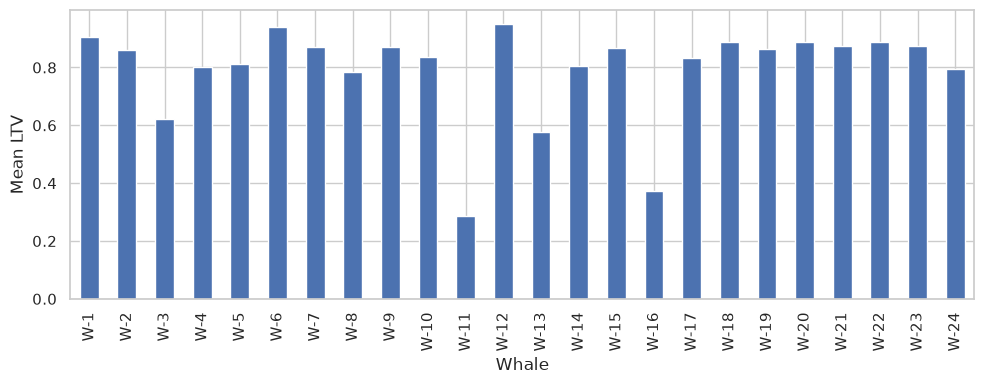

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
panel.groupby("whale_id")["ltv"].mean().reindex(whale_order(panel["whale_id"])).plot(kind="bar", ax=ax)
ax.set_xlabel("Whale")
ax.set_ylabel("Mean LTV")
plt.tight_layout()
plt.show()

The plot above shows mean LTV per whale on active looping days across all 24 whales (W-1..W-17 Morpho, W-18..W-24 Aave). W-11 is lowest (~0.29) and W-16 is next (~0.38); W-12 and W-6 are highest (~0.95/0.94). W-3 sits mid-range (~0.62) with wide day-to-day spread; W-1 is high (~0.91). The Aave whales (W-18..W-24) all sit high (~0.79–0.89), close to the protocol limit.

check the Aave whales W-18..W-24 on active days (open debt)

In [7]:
NEW = [f"W-{i}" for i in range(18, 25)]
new_whales = df[(df.whale_id.isin(NEW)) & (df.borrow_balance_usd >= 1)]
print(new_whales.groupby("whale_id").agg(
    days=("whale_id", "size"),
    ltv_max=("ltv", "max"),
    hf_min=("health_factor", "min"),
).reindex(whale_order(new_whales["whale_id"])))
print()
print(new_whales.loc[new_whales.health_factor < 1, ["whale_id", "date", "ltv", "health_factor", "liquidation_threshold"]])


          days   ltv_max    hf_min
whale_id                          
W-18        87  0.895929  1.026867
W-19        98  0.864220  1.064544
W-20         7  0.887473  1.036651
W-21        37  0.889099  1.034755
W-22         6  0.888853  1.035042
W-23         8  0.875936  1.050305
W-24        77  0.797356  1.153814

Empty DataFrame
Columns: [whale_id, date, ltv, health_factor, liquidation_threshold]
Index: []


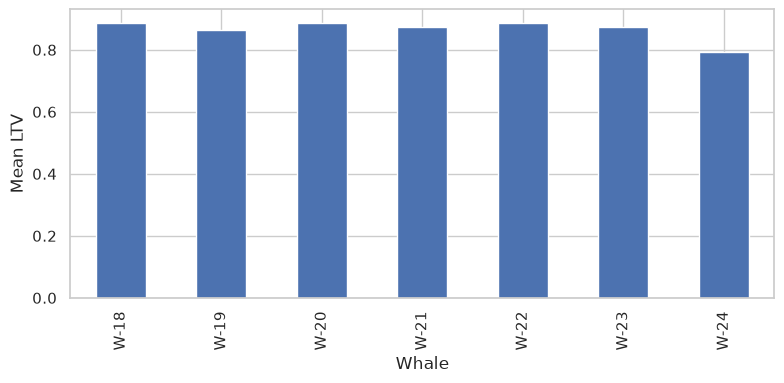

In [8]:
sub = panel[panel.whale_id.isin(NEW)]
fig, ax = plt.subplots(figsize=(8, 4))
sub.groupby("whale_id")["ltv"].mean().reindex(whale_order(sub["whale_id"])).plot(kind="bar", ax=ax)
ax.set_xlabel("Whale")
ax.set_ylabel("Mean LTV")
plt.tight_layout()
plt.show()


mean LTV per Aave whale (W-18..W-24) on active looping days.

### Save features to CSV

In [9]:
panel[["whale_id", "protocol", "date"] + FEATURES].to_csv("panel_cluster_ready.csv", index=False)